# 05- Aprendizaje no supervisado (Clustering)

**Proyecto Final Machine Learning**  
Adriana Lorenzo Mingorance

En este notebook vamos a aplicar técnicas de aprendizaje no supervisado, buscando descubrir estructuras relevantes en los datos.

Para ello, aplicamos K-means como algoritmo de clustering, apoyándonos en técnicas como la reducción de la dimensionalidad (PCA) para facilitar la visualización e interpretación de los resultados.

Así, el análisis se centra en:
identificar grupos de estudiantes con características similares, interpretar los perfiles obtenidos, y analizar su relación con la situación académica real (abandono, graduación, etc).

Para ello, organizamos tres bloques de métodos:
1. **Clustering particional**: K-Means con validacion interna y medidas de estabilidad
2. **Clustering jerárquico**: AGNES con distintos linkages y dendograma
3. **Clustering basado en modelos**: Gaussian Mixture Models (GMM)


Con este enfoque extraemos información útil para interpretar mejor el fenómeno del abandono y del éxito académico

# 0. Imports

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA 
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, silhouette_samples, pairwise_distances
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

semilla = 42
np.random.seed(semilla) #para permutar los datos

## 1. Carga y selección de variables

In [2]:
df = pd.read_csv('../data/rendimiento_estudiantes.csv', sep=';')
objetivo_real = df['objetivo'].copy() #guardamos para comparar al final

print(f"Dataset completo: {df.shape}")

Dataset completo: (4424, 37)


Para clustering usamos el dataset completo (sin split train/test) y seleccionamos variables interpretables y no redundantes

In [3]:
#seleccion de variables para clustering

vars_cluster = [
    #rendimiento académico
    'nota_media_1sem', 'nota_media_2sem', 
    'asignaturas_1sem_aprobadas', 'asignaturas_2sem_aprobadas',
    #acceso y contexto previo
    'nota_admision',
    'nota_cualificacion_previa',
    'edad_al_matricularse',
    #situación administrativa
    'matricula_al_dia',
    'deudor',
    'becado'
]

print('Variables seleccionadas para clustering: ')
for v in vars_cluster:
    print(f' - {v}')

Variables seleccionadas para clustering: 
 - nota_media_1sem
 - nota_media_2sem
 - asignaturas_1sem_aprobadas
 - asignaturas_2sem_aprobadas
 - nota_admision
 - nota_cualificacion_previa
 - edad_al_matricularse
 - matricula_al_dia
 - deudor
 - becado


Seleccionamos estas variables porque describen al estudiante de forma estable y no redundante. 
De igual manera, excluimos variables muy correlacionadas entre sí (por ejemplo, evaluadas y aprobadas), y variables macroeconómicas (ya que no describen al individuo)

In [4]:
df_c = df[vars_cluster].copy()

#codificamos variables binarias si son texto
for col in ['matricula_al_dia', 'deudor', 'becado']:
    if df_c[col].dtype == object:
        df_c[col] = (df_c[col].str.lower().str.strip() == 'si').astype(int)

#escalado
scaler = StandardScaler()
X_sc = scaler.fit_transform(df_c)

print(f'Shape final para clustering: {X_sc.shape}')
print(f'Nulos: {df_c.isnull().sum().sum()}')

Shape final para clustering: (4424, 10)
Nulos: 0


## 2. PCA para entender la varianza

Aplicamos PCA para reducir la dimensionalidad, analizar la varianza explicada y obtener una representqación en dos dimensiones

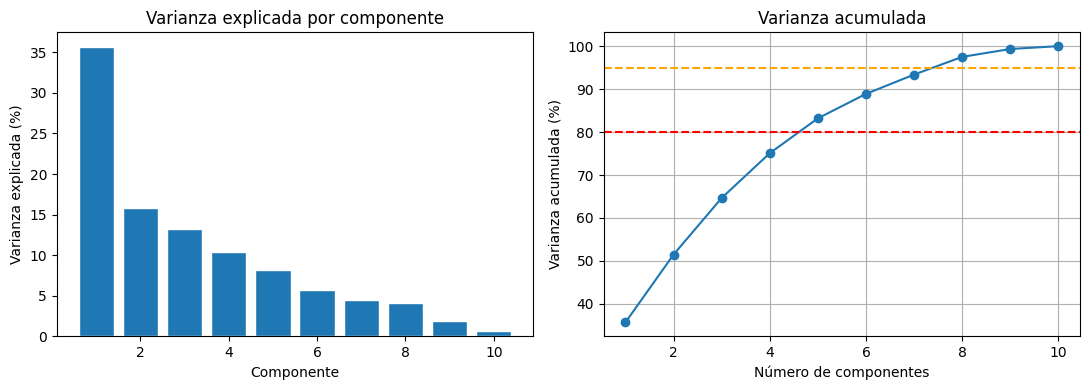

Componentes para explicar 80% de la varianza: 5
Componentes para explicar 95% de la varianza: 8


In [5]:
pca_full = PCA(random_state=42)
pca_full.fit(X_sc)

varianza = pca_full.explained_variance_ratio_ * 100
varianza_acum = np.cumsum(varianza)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

#varianza por componente
axes[0].bar(range(1, len(varianza)+1), varianza, edgecolor='white')
axes[0].set_title('Varianza explicada por componente')
axes[0].set_xlabel('Componente')
axes[0].set_ylabel('Varianza explicada (%)')


#varianza acumulada
axes[1].plot(range(1, len(varianza_acum)+1), varianza_acum, marker='o')
axes[1].axhline(80, color='red', linestyle='--')
axes[1].axhline(95, color='orange', linestyle='--')
axes[1].set_title('Varianza acumulada')
axes[1].set_xlabel('Número de componentes')
axes[1].set_ylabel('Varianza acumulada (%)')

plt.tight_layout()
plt.grid()
plt.savefig('../figuras/pca_varianza.png')
plt.show()

n_80 = np.argmax(varianza_acum >= 80) +1
n_95 = np.argmax(varianza_acum >= 95) +1

print(f'Componentes para explicar 80% de la varianza: {n_80}')
print(f'Componentes para explicar 95% de la varianza: {n_95}')

Como sabemos, la varianza es información, y aquí observamos que con aproximadamente 5 componentes se explica el 80% de la varianza, y con 8 componentes se alcanza el 95%.

Esto indica que la información original puede representarse en menos dimensiones sin una gran pérdida, lo cual facilita mucho la visualización y el análisis.

In [6]:
#proyeccion 2D para visualizar
pca_2d = PCA(n_components=2, random_state=42)
X_pca2 = pca_2d.fit_transform(X_sc)

var1= pca_2d.explained_variance_ratio_[0] * 100
var2= pca_2d.explained_variance_ratio_[1] * 100

print(f'PC1: {var1:.1f} % | PC2: {var2:.1f} % | Total: {var1+var2:.1f} %')

PC1: 35.7 % | PC2: 15.8 % | Total: 51.5 %


# Bloque 1: Clustering particional: K-Means

## 3. Validación interna: elección del número de clusters

Probamos distintos valores de k y usamos tres criterios vistos en clase:

-inercia (método del codo)
-índice de silueta
-índice de Dunn

In [7]:
#funcion auxiliar para el indice de Dunn
def dunn_index(X, labels):
    """
    El índice dunn busca la minima separación inter-cluster, y el diámetro máximo intra-cluster
    """
    unique = np.unique(labels)
    intra_max = []
    for c in unique:
        pts = X[labels == c]
        if len(pts) > 1:
            intra_max.append(pairwise_distances(pts).max())
    inter_min = []
    for i in unique:
        for j in unique:
            if i <j:
                d = pairwise_distances(X[labels == i], X[labels == j]).min()
                inter_min.append(d)
    
    return min(inter_min)/max(intra_max)

inercias = []
siluetas = []
dunns = []
rango_k = range(2,9)

for k in rango_k:
    km = KMeans(n_clusters=k, random_state=semilla, n_init=10)
    labels_k = km.fit_predict(X_sc)

    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X_sc, labels_k))
    dunns.append(dunn_index(X_sc, labels_k))

    print(f'k={k} | inercia={km.inertia_: .1f} | silueta={siluetas[-1]:.4f} | Dunn={dunns[-1]:.4f}')
    

k=2 | inercia= 31877.6 | silueta=0.3741 | Dunn=0.0275
k=3 | inercia= 27857.4 | silueta=0.2352 | Dunn=0.0398
k=4 | inercia= 24673.9 | silueta=0.2581 | Dunn=0.0189
k=5 | inercia= 22263.7 | silueta=0.2472 | Dunn=0.0162
k=6 | inercia= 20277.4 | silueta=0.2592 | Dunn=0.0167
k=7 | inercia= 18533.9 | silueta=0.2643 | Dunn=0.0139
k=8 | inercia= 17233.1 | silueta=0.2729 | Dunn=0.0155


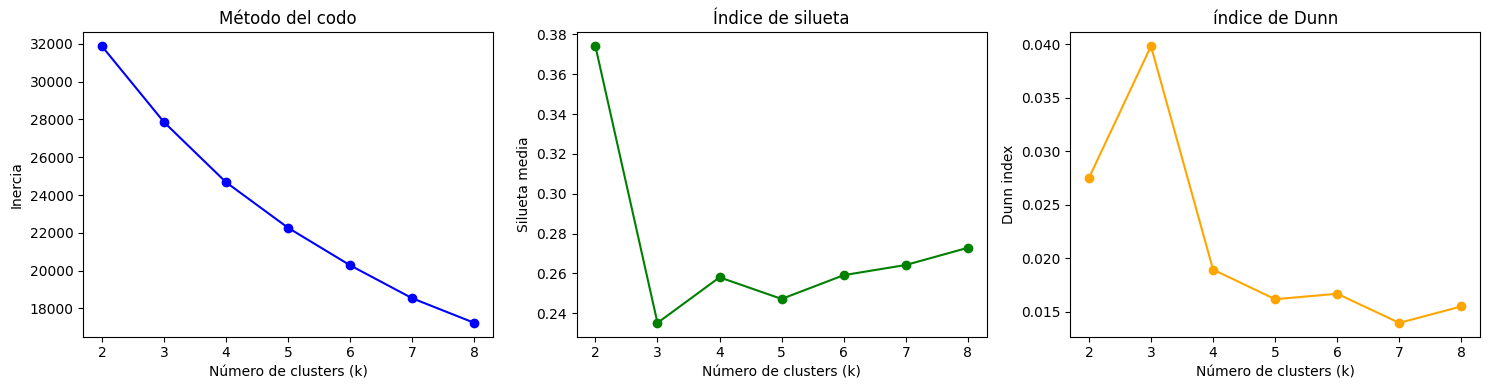

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15,4))

axes[0].plot(list(rango_k), inercias, marker='o', color ='blue')
axes[0].set_title('Método del codo')
axes[0].set_xlabel('Número de clusters (k)')
axes[0].set_ylabel('Inercia')

axes[1].plot(list(rango_k), siluetas, marker='o', color ='green')
axes[1].set_title('Índice de silueta')
axes[1].set_xlabel('Número de clusters (k)')
axes[1].set_ylabel('Silueta media')

axes[2].plot(list(rango_k), dunns, marker='o', color ='orange') 
axes[2].set_title('índice de Dunn')
axes[2].set_xlabel('Número de clusters (k)')
axes[2].set_ylabel('Dunn index')

plt.tight_layout()
plt.savefig('../figuras/eleccion_k_clusters.png')
plt.show()



Vemos que con el codo no indica muy claro cuando empieza a suavizarse, podríamos decir que baja más directo hasta 3-4. Luego, silueta tiene el máximo en k=2, creemos que lo sugerira como óptimo, mientra que Dunn lo tiene claramente en k=3. Vamos a comprobarlo

In [9]:
#vemos cual es el k optimo
k_sil = list(rango_k)[np.argmax(siluetas)]
print(f'K óptimo según silueta: {k_sil}')

k_dunn = list(rango_k)[np.argmax(dunns)]
print(f'K óptimo según dunn: {k_dunn}')

K óptimo según silueta: 2
K óptimo según dunn: 3


Efectivamente, silueta tiene máximo en k=2 y Dunn señala k=3. Ante la ligera discrepancia, optamos por k=3 porque el codo y Dunn convergen y porque tres clusters ofrecen una interpretación más rica, permitiendo distinguir un perfil de alto rendimiento, uno de riesgo y uno intermedio (más útil desde el punto de vista institucional)

## 4. Conectividad: validación adicional

La conectividad mide en qué medida los vecinos más cercanos de cada punto están en el mismo cluster. Cuanto menor, mejor (más conectado internamente).

k=2 | Conectividad=124.1746
k=3 | Conectividad=117.6790
k=4 | Conectividad=180.1813
k=5 | Conectividad=525.7349
k=6 | Conectividad=524.6036
k=7 | Conectividad=638.0583
k=8 | Conectividad=732.7675


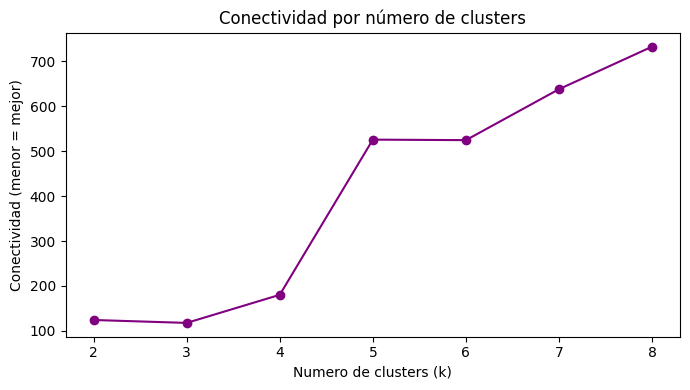

K óptimo según conectividad: 3


In [10]:
#para calcularlo miramos para cad puinto si sus k vecinos más proximos están en el mismo cluster
def connectivity(X, labels, nn=10):
    nbrs = NearestNeighbors(n_neighbors=nn+1).fit(X)
    indices = nbrs.kneighbors(X, return_distance=False)[:, 1:] #excluimos el propio punto
    conn = 0.0
    for i in range(len(X)):
        for j_rank, j in enumerate(indices[i], start=1):
            if labels[i] != labels[j]:
                conn += 1.0/ j_rank
    return conn

conns = []
for k in rango_k:
    km = KMeans(n_clusters=k, random_state=semilla, n_init=10)
    labels_k = km.fit_predict(X_sc)

    conns.append(connectivity(X_sc, labels_k))
    print(f'k={k} | Conectividad={conns[-1]:.4f}')

plt.figure(figsize=(7,4))
plt.plot(list(rango_k), conns, marker='o', color='purple')
plt.title('Conectividad por número de clusters')
plt.xlabel('Numero de clusters (k)')
plt.ylabel('Conectividad (menor = mejor)')
plt.tight_layout()
plt.savefig('../figuras/conectividad_clusters.png')
plt.show()


k_conn = list(rango_k)[np.argmin(conns)]
print(f'K óptimo según conectividad: {k_conn}')
    

La conectividad mide hasta qué punto los vecinos más cercanos de cada observación están en el mismo cluster. Como vemos en la gráfica, aunque k=2 también es bajo, k=3 es el mínimo, por lo que continuamos con nuestra elección de k=3 para el número de clusters realizada antes.

## 5. K-means final

Entrenamos ahora K-means con el valor de k seleccionado y asignamos un cluster a cada estudiante

In [11]:
K_final = 3 #codo, dunn y conectividad convergen

km_final = KMeans(n_clusters=K_final, random_state=semilla, n_init=10)
labels = km_final.fit_predict(X_sc)

df['cluster'] = labels
df_c['cluster'] = labels

print(f'K final: {K_final}')
print(f'Silueta final: {silhouette_score(X_sc, labels):.4f}')
print(f'Dunn index final: {dunn_index(X_sc, labels):.4f}')
print(f'\nTamaño de cada cluster:')
print(pd.Series(labels).value_counts().sort_index())

K final: 3
Silueta final: 0.2352
Dunn index final: 0.0398

Tamaño de cada cluster:
0    2505
1     909
2    1010
Name: count, dtype: int64


## 6. Gráfico de silueta por punto individual

El gráfico de silueta individual nos permitirá ver qué observaciones están bien asignadas (si es proximo a 1), en la frontera entre clusters (si es aprox. = 0) o posiblemente mal asignadas ( si <0).

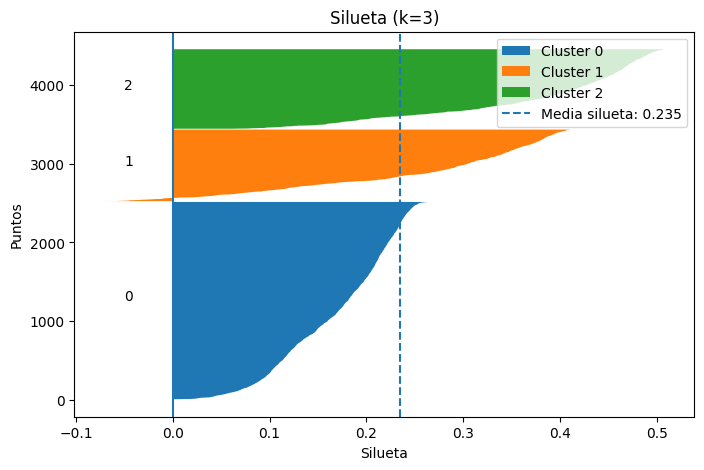

Media silueta: 0.2352
Puntos con Si < 0 (posiblemente mal asignados): 42


In [12]:
sil_vals = silhouette_samples(X_sc, labels)

plt.figure(figsize=(8,5))

y=10
for i in range(K_final):
    cluster_sil = np.sort(sil_vals[labels == i])
    
    plt.fill_betweenx(range(y, y+len(cluster_sil)), 0, cluster_sil, label=f'Cluster {i}')
    plt.text(-0.05, y+len(cluster_sil)/2, str(i))

    y+= len(cluster_sil) +10

#linea media
media = np.mean(sil_vals)
plt.axvline(media, linestyle='--', label=f'Media silueta: {media:.3f}')
plt.axvline(0)

plt.xlabel('Silueta')
plt.ylabel('Puntos')
plt.legend()
plt.title(f'Silueta (k={K_final})')

plt.show()

print(f'Media silueta: {media:.4f}')
print(f'Puntos con Si < 0 (posiblemente mal asignados): {np.sum(sil_vals < 0)}')

El gráfico de silueta muestra la distribución de Si por cluster. Vemos una media de 0.235, coherente con el valor obtenido en la selección de k. Solo 42 observaciones presentan Si<0 (frente el 4424 de estudiantes, es solo el 0.95% del total), lo que indica que gran parte de los estudiantes están bien asignados. 

Sin embargo, los tres clusters presentan una distribución asimétrica con ligera cola izquierda pronunciada (Si cerca de 0) lo que refleja que existe solapamiento entre perfiles, especialmente en el cluter intermedio.

## 7. Visualización en 2D

Visualizamos los clusters en el espacio reducido de PCA y comparamos con la situación real del estudiante

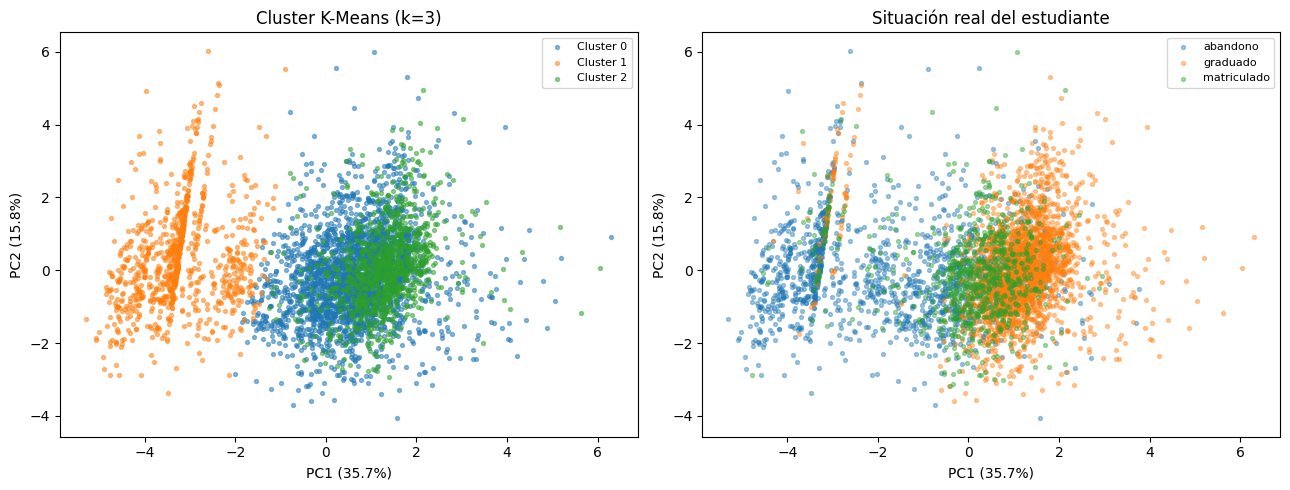

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

#PCA coloreado por cluster
for cl in range(K_final):
    mask = labels == cl
    axes[0].scatter(X_pca2[mask, 0], X_pca2[mask, 1], s=8, alpha=0.5, label=f'Cluster {cl}')

axes[0].set_title(f'Cluster K-Means (k={K_final})')
axes[0].set_xlabel(f'PC1 ({var1:.1f}%)')
axes[0].set_ylabel(f'PC2 ({var2:.1f}%)')
axes[0].legend(fontsize=8)

#PCA coloreado por objetivo real
for obj in objetivo_real.unique():
    mask = objetivo_real == obj 
    axes[1].scatter(X_pca2[mask, 0], X_pca2[mask, 1], s=8, alpha=0.4, label=obj)

axes[1].set_title(f'Situación real del estudiante')
axes[1].set_xlabel(f'PC1 ({var1:.1f}%)')
axes[1].set_ylabel(f'PC2 ({var2:.1f}%)')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig('../figuras/clusters_pca_2d.png')
plt.show()

La proyección en 2D mediante PCA permite visualizar la estructura de los datos.
Observamos que K-means separa los estudiantes en dos zonas diferenciadas, principalmente a lo largo de la primera componente (PC1, con 35.7% de varianza), que concentra gran parte de la variabiliad.

En el extremo negativo de PC1 vemos una franja compacta que K_Means asigna en su totalidad al cluster 0, y que al comparar con la situación real corresponde mayoritariamente a estudiantes en situación de abandono. Esta correspondencia, obtenida sin usar la variable objetivo, demuestra que el clustering ha capturado una señal real y no un artefacto.

En la zona derecha (PC1 positivo), los clusters 1 y 2 se solapan considerablemente, al igual que graduados y matriculados en la situación real. Esto confirma que la frontera estre estos dos perfiles es más difuso, coherente con los valores bajos de silueta que hemos visto antes

## 8. Interpretación de perfiles por cluster

Calculamos la media de cada variable dentro de cada cluster para interpretar los perfiles obtenidos

In [14]:
perfil = df_c.groupby('cluster')[vars_cluster].mean().round(2)

print('PERFIL MEDIO POR CLUSTER:')
print(perfil.to_string())

PERFIL MEDIO POR CLUSTER:
         nota_media_1sem  nota_media_2sem  asignaturas_1sem_aprobadas  asignaturas_2sem_aprobadas  nota_admision  nota_cualificacion_previa  edad_al_matricularse  matricula_al_dia  deudor  becado
cluster                                                                                                                                                                                            
0                  12.68            12.64                        5.72                        5.39         127.17                     132.29                 23.38              0.91    0.10     0.0
1                   2.48             0.64                        0.50                        0.09         126.12                     132.26                 25.86              0.69    0.20     0.1
2                  12.93            12.89                        5.99                        5.98         127.27                     133.74                 20.64              0.97    0.06   

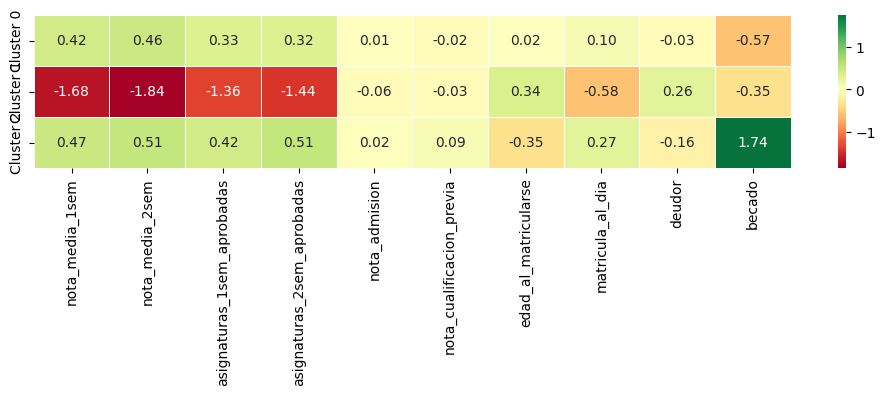

In [15]:
#heatmap de perfiles
perfil_sc = pd.DataFrame(km_final.cluster_centers_, columns=vars_cluster)

plt.figure(figsize=(10,4))
sns.heatmap(
    perfil_sc,
    annot=True,
    fmt='.2f',
    cmap='RdYlGn',
    center=0,
    linewidths=0.5,
    linecolor='white',
    xticklabels = vars_cluster,
    yticklabels = [f'Cluster {i}' for i in range(K_final)]
)

plt.tight_layout()
plt.savefig('../figuras/heatmap_centroides.png')
plt.show()



Nuestro heatmap muestra los centroides de cada clustrer en valores estandarizados, nos permite caracterizar cada uno como un perdil de estudiante diferenciado:

El cluster 0 presenta valores por encima de la media en variables académicas (nota media y asignaturas aprobadas sobre 0.4-0.46), con matrícula al día y veca negativa (-0.57). Esto nos indica como seguramente estemos hablando de un perfil típico de estudiante activo con reminiento sólido.

Por el contrario, el Cluster 1 presenta valores claramente por debajo de la media, negativos, en estas variables, (nota media 1sem -1.68, nota media 2 sem -1,84, asignaturas aprobadas 1sem: -1.36, 2sem:-1.44). Son estudiantes con rendimiento miuy por debajo de la media, mayor edad al matricularse y sin beca (tambien negativa). Es el perfil más asociado al abandono, como confirmó el scatter PCA.

Por último, el cluster 2, es bastante similar al cluster 0 (ya hemos visto en el scatter su solapamiento, ahora también en los centroides), pero destaca por una veca muy altaa (1.74, el valor más extremo del heatmap) y menor edad al matricularse. Es el perfil seguramente más asociado a graduados con apoyo institucional.

Las variables macroeconómicas y de acceso (nota admisión, cualificación previa) no muestran diferencias relevanres entre clusters, tienen valores cercanos a 0, lo que refuerza la conclusión de las tareas supervisadas: el rendimiento una vez en la universidad es más determinante que el historial previo.

## 9. Relación entre clusters y objetivo real

Analizamos cómo se distribuye la situación real del estudiante dentro de cada cluster

In [16]:
tabla = pd.crosstab(
    df['cluster'],
    objetivo_real,
    normalize='index'
).round(3) * 100

print('Situación real dentro de cada cluster')
print(tabla.to_string())

Situación real dentro de cada cluster
objetivo  abandono  graduado  matriculado
cluster                                  
0             23.6      52.9         23.6
1             82.4       8.5          9.1
2              8.1      80.0         11.9


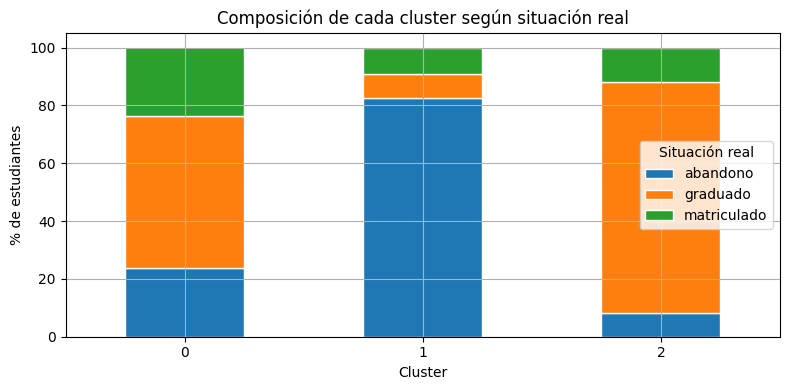

In [17]:
tabla.plot(kind='bar', stacked=True, figsize=(8,4), edgecolor='white')
plt.title('Composición de cada cluster según situación real')
plt.xlabel('Cluster')
plt.ylabel('% de estudiantes')
plt.xticks(rotation=0)
plt.legend(title='Situación real')
plt.tight_layout()
plt.grid()
plt.savefig('../figuras/clusters_vs_objetivos.png')
plt.show()



La composición de los clusters muestra una clara diferencia en la situación acdémica de los estudiantes.

El cluster 0 está mayoritariamente formado por estudiantes graduados,lo que sugiere que agrupa perfiles con mejor rendimiento académico, aunque es más heterogéneo, con mezcla de las tres situaciones, actuando como un perfil quzá mas intermedio.

Por el contrario, el Cluster 1 presenta una proporción muy elevada de abandono (casi el 80%) y pocos graduados, constituyendi el perfil de riesgo más claro.

El cluster 2 agrupa alrededor del 85% de graduados, representando el perdil de éxito.

La homogeneidad del Cluster 1 es especialmente relevante: sugiere que los estudiantes en riesgo presentan un patrón de caracterísitcas detectables de forma temprana, lo que la puierta a intervenciones prventivas (basadas en datos) antes de que abandonen.

Esto nos confirma que el clustering ha sido capaz de identificar grupos de estudiantes con trayectorias académicas claramente diferenciadas, sin haber utilizado la variable objetivo durante el training.

# Bloque 2: Clustering Jerárquico: AGNES

## 10. Clustering Jerárquico con distintos linkages

El clustering jerárquico (AGNES y DIANA) agrupa observaciones de forma ascendente (siguiendo el bottom-up estudiado) parte de cada punto como su propio cluster y va fusionando los más similares. A diferencia de de K-means, no requiere especificar el K de antemano sino que lo hallaremos. Comparamos cuatro métodos de linkage vistos en clase.

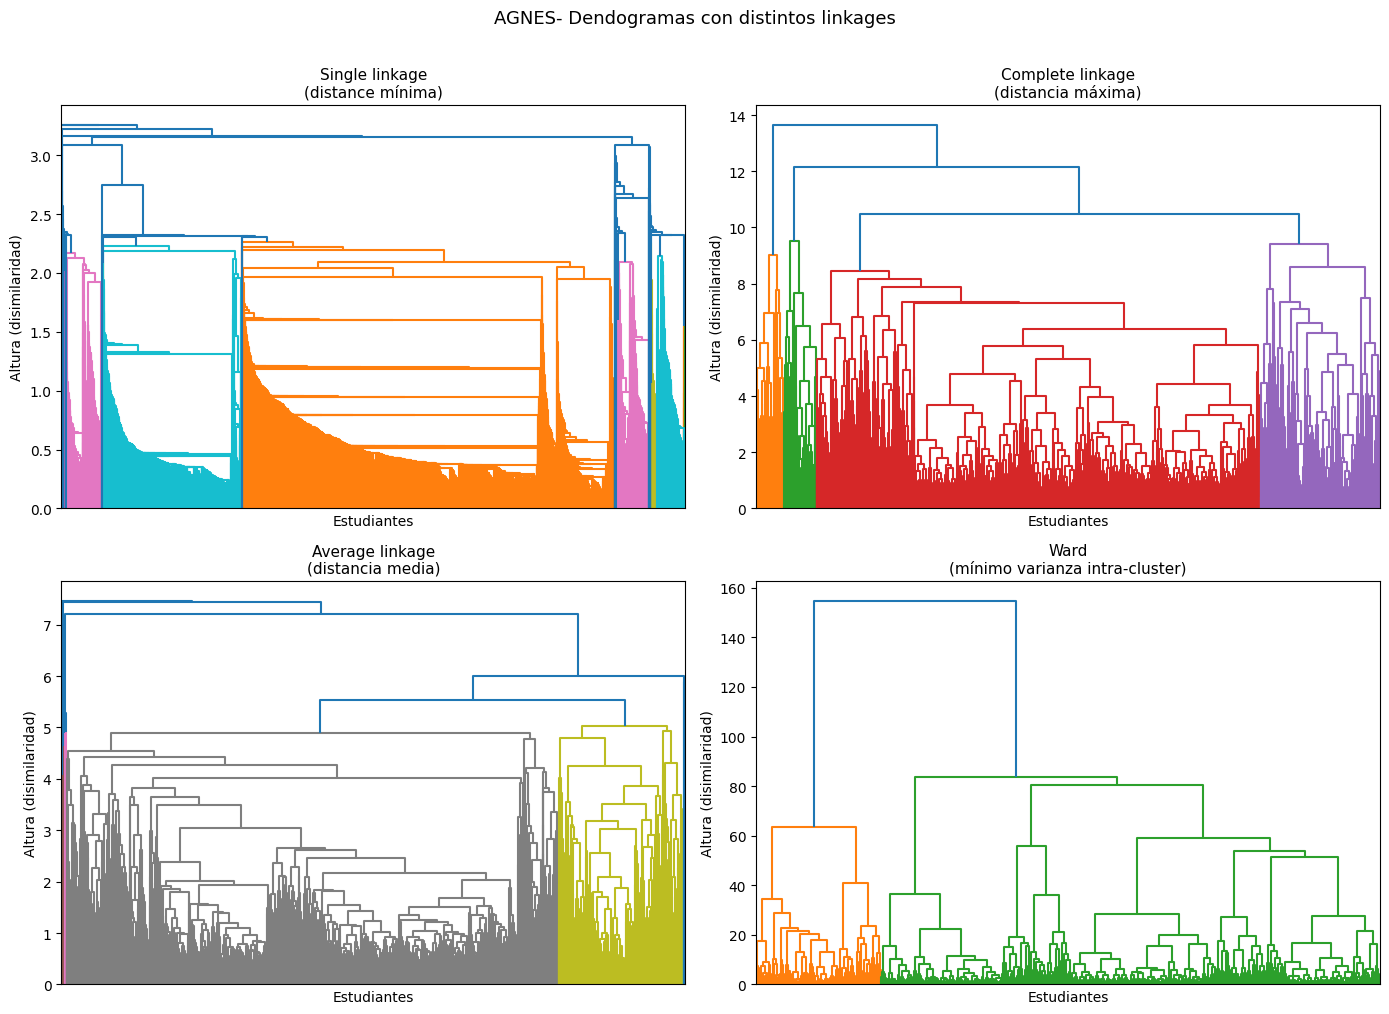

SIngle linkage tiende a producir singletons en cadena
Ward y complete producen clusters más equilibrados


In [18]:
linkage_methods = ['single', 'complete', 'average', 'ward']
linkage_nombres = [
    'Single linkage\n(distance mínima)',
    'Complete linkage\n(distancia máxima)',
    'Average linkage\n(distancia media)',
    'Ward\n(mínimo varianza intra-cluster)'
]

fig, axes = plt.subplots(2,2, figsize=(14,10))
axes = axes.flatten()

for i, (method, nombre) in enumerate(zip(linkage_methods, linkage_nombres)):
    Z = linkage(X_sc, method=method)
    dendrogram(Z, ax=axes[i], no_labels=True)
    axes[i].set_title(nombre, fontsize=11)
    axes[i].set_xlabel('Estudiantes')
    axes[i].set_ylabel('Altura (disimilaridad)')

plt.suptitle('AGNES- Dendogramas con distintos linkages', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

print("SIngle linkage tiende a producir singletons en cadena")
print('Ward y complete producen clusters más equilibrados')

Los cuatro dendrogramas ilustran el impacto de la elección del linkage, una de las 'small decisions, big consequences' del clustering jerárquico.
Single muestra claramente el efecto candena: produce clusters muy desequilibrados donde la mayoría de observaciones quedan agrupadas en un único cluster masivo.
Average mejora el equilibrio pero la estructura sigue sin ser muy clara.
Complete produce clusters más equilibrados pero con alturas muy similares, dificlutando la elección del corte.
Ward es el método que produce claramente la estructura más interpretable: tres ramas diferenciadas con saltos de altura definidos, lo que facilita decidir donde cortar.

Esto es coherente con la teoría: Ward minimiza la varianza intra-cluster en cada fusíón, produciendo los grupos más compactos e interpretabels. Lo elegimos para nuestro análisis.

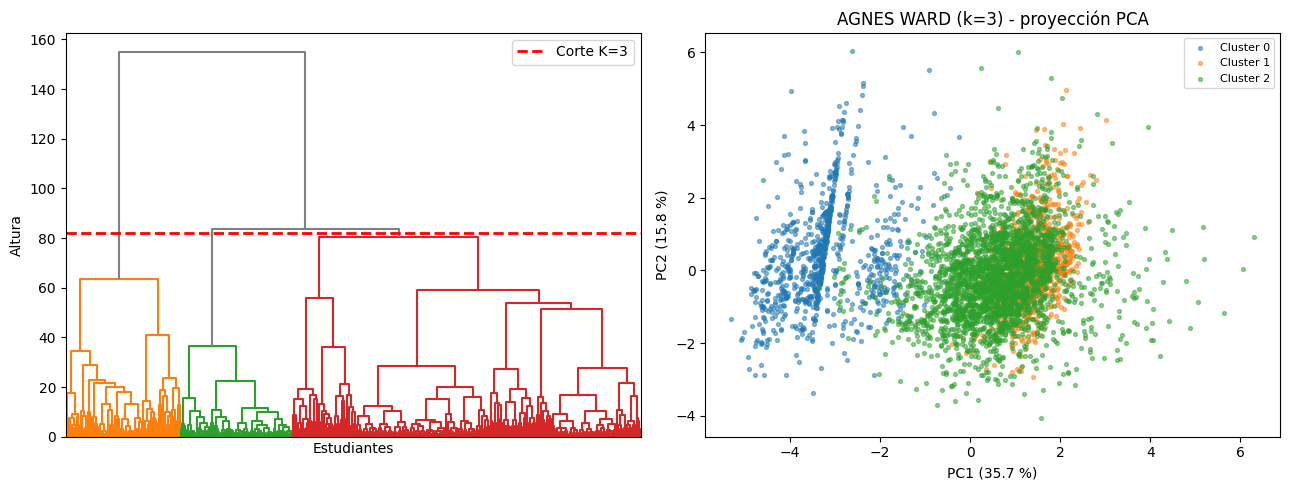

In [19]:
#usamos Ward linkage (el más robusto según la teoría)
Z_ward = linkage(X_sc, method='ward')

fig, axes = plt.subplots(1,2, figsize=(13,5))

#dendrograma con línea de corte
dendrogram(Z_ward, ax=axes[0], no_labels=True,
           color_threshold=Z_ward[-K_final+1, 2],
           above_threshold_color='gray')
altura_corte = (Z_ward[-K_final+1, 2]+ Z_ward[-K_final, 2]) / 2
axes[0].axhline(y=altura_corte, color='red', linestyle='--',
                linewidth=2, label=f'Corte K={K_final}')
axes[0].set_xlabel('Estudiantes')
axes[0].set_ylabel('Altura')
axes[0].legend()

#resultado del clustering jeráquico 
labels_hier = fcluster(Z_ward, t=K_final, criterion='maxclust') -1
for cl in np.unique(labels_hier):
    mask= labels_hier == cl
    axes[1].scatter(X_pca2[mask, 0], X_pca2[mask, 1], s=8, alpha=0.5, label=f'Cluster {cl}')

axes[1].set_title(f'AGNES WARD (k={K_final}) - proyección PCA')
axes[1].set_xlabel(f'PC1 ({var1:.1f} %)')
axes[1].set_ylabel(f'PC2 ({var2:.1f} %)')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig('../figuras/agnes_ward.png')
plt.show()


Aplicando un corte en el dendrograma de Ward que genera k=3 clusters, el resultado es muy similar al obtenido con K-Means. La proyección PCA muestra la misma estructura: un cluster compacto en la parte parte negativa (el perfil de abandono) y dos cluster solapados a la derecha (los de éxito e intermedio).

Esta concordoncia entre dos algoritmos muy distintos (K_Means y AGNES jerárquico) refuerza la robustez a los perfiles encontrados. Es una estructura real presente en los datos

In [20]:
#comparación de siluetas K-Means vs AGNES
sil_kmeans = silhouette_score(X_sc, labels)
sil_hier= silhouette_score(X_sc, labels_hier)
dunn_hier = dunn_index(X_sc, labels_hier)

print("Comparativa K-Means vs AGNES:")
print(f'Silueta K-Means: {sil_kmeans:.4f}')
print(f'Silueta AGNES: {sil_hier:.4f}')
print(f'Dunn AGNES: {dunn_hier:.4f}')

Comparativa K-Means vs AGNES:
Silueta K-Means: 0.2352
Silueta AGNES: 0.1954
Dunn AGNES: 0.0643


K-Means obtiene una silueta ligeramente superior (0.235 vs 0.195) lo que indica que sus clusters están algo mejor definidos internamente. Sin embargo, AGNES Ward obtiene un DUnn más alto (0.064), reflejando mejor separación entre clusters.

Ambos métodos encuentran igual estructura en los datos. 

# Bloque 3: Clustering basado en Modelos (GMM)

Aunque en clase lo hemos visto por encima, lo añadimos como extra para complementar nuestro análisis. Los GMM son un enfoque de clustering que asigna probabilidad de pertenencia a cada cluster y pueden capturar clusters con formas elípticas arbitrarias.



## 11. GMM
EL algoritmo EM aprende el numero de gaussianas, su localización (media) y si convarinza

k = 2. BIC=87735.8. AIC=86898.1
k = 3. BIC=-14631.5. AIC=-15891.2
k = 4. BIC=-22806.8. AIC=-24488.6
k = 5. BIC=-34129.3. AIC=-36233.2
k = 6. BIC=-71433.3. AIC=-73959.2
k = 7. BIC=-80660.0. AIC=-83608.0
k = 8. BIC=-84797.8. AIC=-88167.8


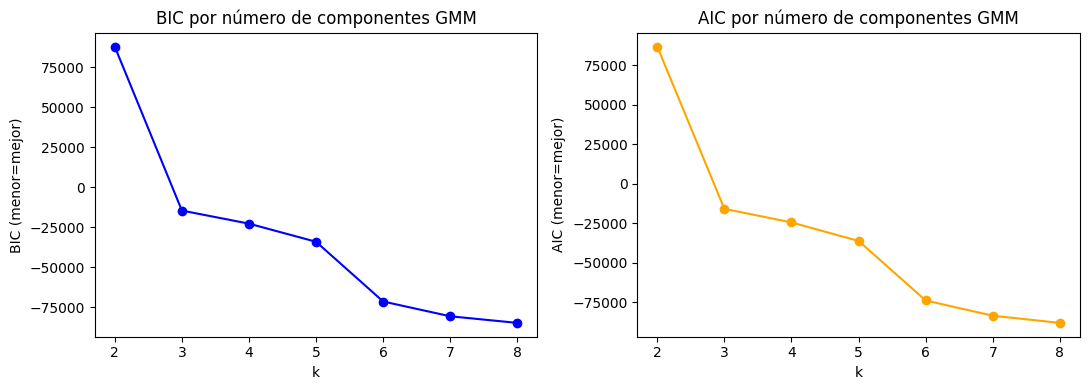

K óptimo según BIC: 8


In [21]:
#elegimos k con BIC: penaliza complejidad del modelo (menor BIC, mejor)
bics = []
aics = []

for k in rango_k:
    gmm = GaussianMixture(n_components=k, random_state=semilla, n_init=5)
    gmm.fit(X_sc)
    bics.append(gmm.bic(X_sc))
    aics.append(gmm.aic(X_sc))
    print(f'k = {k}. BIC={bics[-1]:.1f}. AIC={aics[-1]:.1f}')

fig, axes = plt.subplots(1,2, figsize=(11,4))
axes[0].plot(list(rango_k), bics, marker= 'o', color='blue', label='BIC')
axes[0].set_title('BIC por número de componentes GMM')
axes[0].set_xlabel('k')
axes[0].set_ylabel('BIC (menor=mejor)')

axes[1].plot(list(rango_k), aics, marker='o', color='orange', label='AIC')
axes[1].set_title('AIC por número de componentes GMM')
axes[1].set_xlabel('k')
axes[1].set_ylabel('AIC (menor=mejor)')

plt.tight_layout()
plt.savefig('../figuras/gmm_bic_aic.png')
plt.show()

k_bic = list(rango_k)[np.argmin(bics)]
print(f'K óptimo según BIC: {k_bic}')


A diferencia de K-Means y AGNES, los criterios BIC y AIC del GMM no muestran un mínimo claro en el rango explorado (ambos siguen decreciendo hasta k=8).
Esto indica que el modelo gaussiano encuentra siempre beneficio en añadir más componentes, posiblemente porque los datos no siguen distribuciones normales puras o porque hay subgrupos pequeños que el modelo intenta capturar.

Dado que BIC y AIC no siguen  los criterios de validación interna de K-Means y AGNES, fijamos k=3 porque también vemos un mínimo importante ahí en ambas gráficas y por manter la comparabiliad entre métodos.

In [22]:
#ajustamos GMM con k óptimo
gmm_final = GaussianMixture(n_components=3, random_state=semilla, n_init=5) #fijamos k=3 por comparabilidad
gmm_final.fit(X_sc)
labels_gmm = gmm_final.predict(X_sc)
probs_gmm = gmm_final.predict_proba(X_sc) #probabilidades de pertenencia

sil_gm = silhouette_score(X_sc, labels_gmm)
print(f'GMM K=3. Silueta: {sil_gm:.4f}')
print(f'Tamaño de clusters GMM')
print(pd.Series(labels_gmm).value_counts().sort_index())

#prob media de pertenencia 
max_probs = probs_gmm.max(axis=1)
print(f'\nProb media de asignación al cluster ganador: {max_probs.mean():.4f}')
print(f'Puntos con prob < 0.6 (Asignación incierta): {(max_probs < 0.6).sum()}')

GMM K=3. Silueta: 0.3227
Tamaño de clusters GMM
0     503
1     870
2    3051
Name: count, dtype: int64

Prob media de asignación al cluster ganador: 1.0000
Puntos con prob < 0.6 (Asignación incierta): 0


Con k = 3 fijado por comparabilidad, GMM obtiene la mejor silueta de los métodos (0.323) y una prob de asignación media de 1, indicando que todos los estudiantes asociados con total certeza a su cluster

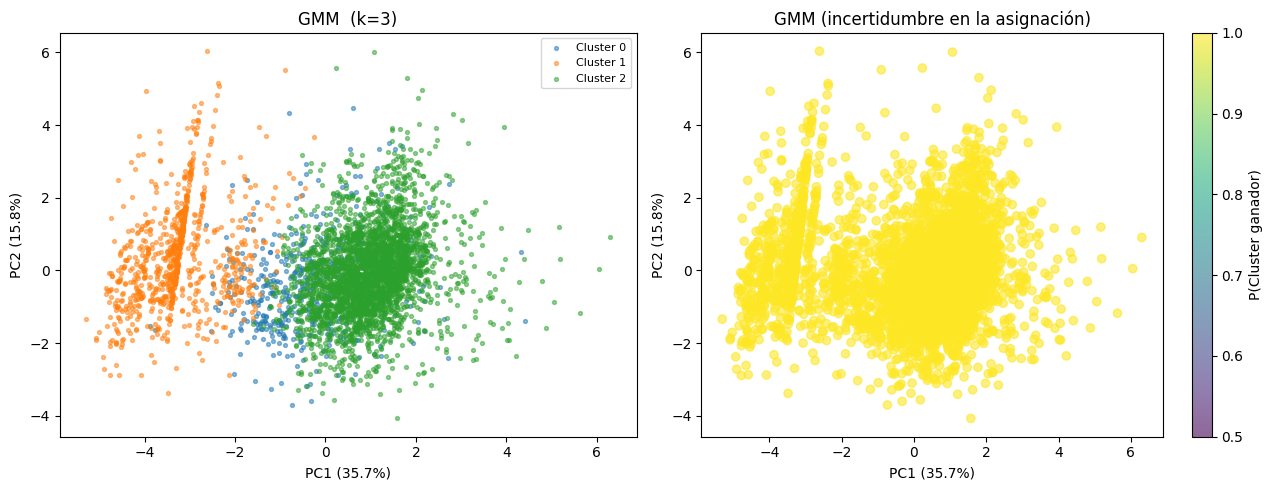

In [23]:
#visualizacion GMM en 2D
fig, axes = plt.subplots(1,2, figsize=(13,5))

for cl in range(3):
    mask = labels_gmm == cl
    axes[0].scatter(X_pca2[mask,0], X_pca2[mask,1], s=8, alpha=0.5, label=f'Cluster {cl}')

axes[0].set_title(f'GMM  (k=3)')
axes[0].set_xlabel(f'PC1 ({var1:.1f}%)')
axes[0].set_ylabel(f'PC2 ({var2:.1f}%)')
axes[0].legend(fontsize=8)

#coloreado por incertidumbre (prob. del cluster ganador)
sc = axes[1].scatter(X_pca2[:,0], X_pca2[:,1], c=max_probs, alpha=0.6, vmin=0.5, vmax=1)
plt.colorbar(sc, ax=axes[1], label='P(Cluster ganador)')
axes[1].set_title('GMM (incertidumbre en la asignación)')
axes[1].set_xlabel(f'PC1 ({var1:.1f}%)')
axes[1].set_ylabel(f'PC2 ({var2:.1f}%)')

plt.tight_layout()
plt.savefig('../figuras/gmm_clusters.png')
plt.show()

El gráfico izquierdo muestra que GMM con k=3 identifica la misma estructura que K-Means y AGNES: un cluster compacto en el extremo negativo de PC1 (seguramente el de abandono) y dos cluster solapapos en la zona derecha.

El gráfico de la derecha nos confirma que todos los estudiantes están asignados con prob=1 (todo amarillo, ninguno de otro color).

Esto nos confirma que los tres perfiles están bien sepaarados desde la perspectiva gaussiana. 

## 12. Comparativa final de métodos

In [24]:
resumen = pd.DataFrame({
    'Método': ['K-Means', 'AGNES', 'GMM'], 
    'k': [K_final, K_final, K_final],
    'Silueta': [
        round(silhouette_score(X_sc, labels), 4),
        round(silhouette_score(X_sc, labels_hier), 4),
        round(silhouette_score(X_sc, labels_gmm), 4)
    ],
    'Dunn': [
        round(dunn_index(X_sc, labels), 4),
        round(dunn_index(X_sc, labels_hier), 4),
        round(dunn_index(X_sc, labels_gmm), 4),
    ]
})

print('Comparativa final de métodos:')
print(resumen.to_string(index=False))

Comparativa final de métodos:
 Método  k  Silueta   Dunn
K-Means  3   0.2352 0.0398
  AGNES  3   0.1954 0.0643
    GMM  3   0.3227 0.1717


GMM como hemos dicho tiene con creces la mejor silueta (0.3227) y el mejor Dunn(0.1717), seguido de K-Means y AGNES. A pesasr de ciertas diferencias, los tres convergen en k=3 e identifican la estructura. GMM destaca porque es más flexible con distribuciones elípticas, lo que explica sus mejores métricas

## 13. Resumen para el informe

In [25]:
print("Resumen para el informe: TAREA 3: CLUSTERING")


print(f'Variables usadas: {vars_cluster}')
print(f'K final K-Means: {K_final}')
print(f" Índice de silueta: {silhouette_score(X_sc, labels):.4f}")
print(f" Dunn index: {dunn_index(X_sc, labels):.4f}")
print(f" Variabels usadas: {vars_cluster}")
print(f'Varianza explicada por PCA 2D: {var1+var2:.1f} %')

print('\nTamaño de clusters: ')
print(pd.Series(labels).value_counts().sort_index().to_string())



Resumen para el informe: TAREA 3: CLUSTERING
Variables usadas: ['nota_media_1sem', 'nota_media_2sem', 'asignaturas_1sem_aprobadas', 'asignaturas_2sem_aprobadas', 'nota_admision', 'nota_cualificacion_previa', 'edad_al_matricularse', 'matricula_al_dia', 'deudor', 'becado']
K final K-Means: 3
 Índice de silueta: 0.2352
 Dunn index: 0.0398
 Variabels usadas: ['nota_media_1sem', 'nota_media_2sem', 'asignaturas_1sem_aprobadas', 'asignaturas_2sem_aprobadas', 'nota_admision', 'nota_cualificacion_previa', 'edad_al_matricularse', 'matricula_al_dia', 'deudor', 'becado']
Varianza explicada por PCA 2D: 51.5 %

Tamaño de clusters: 
0    2505
1     909
2    1010


El análisis no supervisado identifica tres perfiles claramente diferenciados en los 4424 estudiantes. El Cluster 1 (909 estudiantes) es el perfil de riesgo, fuertemente asociado al abandono. El cluster 2(1010) representa el perfil de éxito con beca. El cluster 0 (2505 estudiantes) es el perfil mayoritario e intermiedo. 

PCA retiene el 51.5% de la varianza en 2D, suficiente para visualizar la estructura principal. TOdo esto es coherente con neustras hipótesis iniciales y con los hallazgos de las tareas supervisadas, lo que refuerza su validez como herramienta de interpretación del abandono académico.